# Thermal noise

With a `thermal_energy` $kT > 0$ the elements follow the overdamped Langevin equation of
Sandersius & Newman, *Phys. Biol.* **5** (2008) 015002 (Eq. 1 and 2). Each step of length $\Delta t$ moves
every coordinate of every element by

$$\Delta x = \frac{F}{\eta}\,\Delta t + \sqrt{2 D\,\Delta t}\;\xi, \qquad \xi \sim \mathcal N(0, 1)$$

The noise stands for the thermal and active agitation of the cytoskeleton. Two numbers describe it:

- The **thermal energy** $kT$, the parameter that is set: how far the noise can push elements up their
  potential wells. Compare it with the well depth $u_0$ to judge whether bonds hold.
- The diffusion coefficient $D = kT/\eta$ (Einstein relation): how fast a free element diffuses. It follows
  from $kT$ and the drag $\eta$ of the element's cell type, so all cell types are at the same temperature.
  In the runs below $\eta = 1$, so $D$ and $kT$ are the same number.

With $kT = 0$ (the default) there is no noise and a run is deterministic. With noise a run is still
reproducible: every random number is computed from `random_seed`, the step, the element and the axis.

All data here comes from the C++ solver through the `thermal_noise` example:

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.thermal_noise
D=mechanics/micromechanics/docs/notebooks/data
for dims in 1 2 3; do $E diffusion $dims > $D/noise_diffusion_${dims}d.csv; done
for ratio in 0.0002 0.001 0.0025 0.005; do $E pair $ratio > $D/noise_pair_$ratio.csv; done
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load(name, **kwargs):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = dict(item.split("=") for item in header)
    params = {key: (value if key == "experiment" else float(value)) for key, value in params.items()}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1, **kwargs)

## Free diffusion

4000 elements that do not interact start at rest. Their mean squared displacement must grow linearly,

$$\langle |\Delta \mathbf{x}|^2 \rangle = 2\,d\,D\,t$$

with $d$ the number of dimensions. This checks the amplitude of the noise and that successive steps are independent.

1D: D from the slope = 0.1601, set to 0.1600 (+0.0%)
2D: D from the slope = 0.1587, set to 0.1600 (-0.8%)
3D: D from the slope = 0.1595, set to 0.1600 (-0.3%)


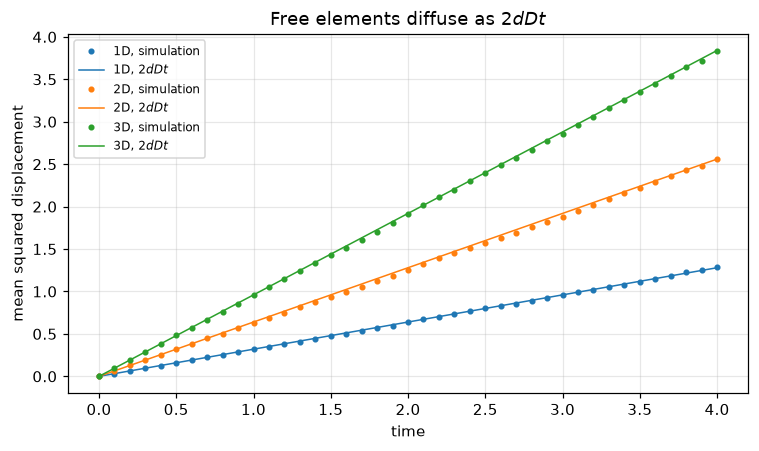

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.2))

for dims in (1, 2, 3):
    params, table = load(f"noise_diffusion_{dims}d.csv")
    diffusion = params["diffusion_coefficient"]
    line, = ax.plot(table["time"], table["mean_squared_displacement"], ".", label=f"{dims}D, simulation")
    ax.plot(table["time"], 2 * dims * diffusion * table["time"], color=line.get_color(), linewidth=1, label=f"{dims}D, $2 d D t$")

    measured = np.polyfit(table["time"], table["mean_squared_displacement"], 1)[0] / (2 * dims)
    # 4000 elements: the slope is known to a few percent
    assert abs(measured / diffusion - 1) < 0.05, f"{dims}D: measured D = {measured}"
    print(f"{dims}D: D from the slope = {measured:.4f}, set to {diffusion:.4f} ({100 * (measured / diffusion - 1):+.1f}%)")

ax.set(xlabel="time", ylabel="mean squared displacement", title="Free elements diffuse as $2 d D t$")
ax.legend(fontsize=8)
fig.tight_layout()

## Thermal equilibrium of a bound pair

Two elements bound by the pair potential settle into thermal equilibrium, where the probability of finding
them at distance $r$ is the Boltzmann distribution (in three dimensions, with the $r^2$ of the spherical shell):

$$p(r) \propto r^2\,\exp\!\left(-\frac{V(r)}{kT}\right), \qquad kT = D\,\eta$$

This is a demanding check: it only comes out right if the noise amplitude, the drag and the forces are
mutually consistent. Below, 400 pairs are sampled 20 times each at three temperatures.

For a stiff well and low temperature the distribution is a narrow Gaussian of variance $kT/k$, with $k$ the
stiffness at the minimum (equipartition). As the temperature rises the pair explores the softer outer side of
the well and the distribution becomes wider and skewed.

    kT/k    kT/u0    variance       kT/k   Boltzmann   sim vs kT/k   sim vs Boltzmann
  0.0002    0.006   2.096e-04  2.000e-04   2.031e-04         +4.8%              +3.2%
   0.001    0.032   1.120e-03  1.000e-03   1.087e-03        +12.0%              +3.1%
  0.0025    0.080   3.289e-03  2.500e-03   3.241e-03        +31.6%              +1.5%


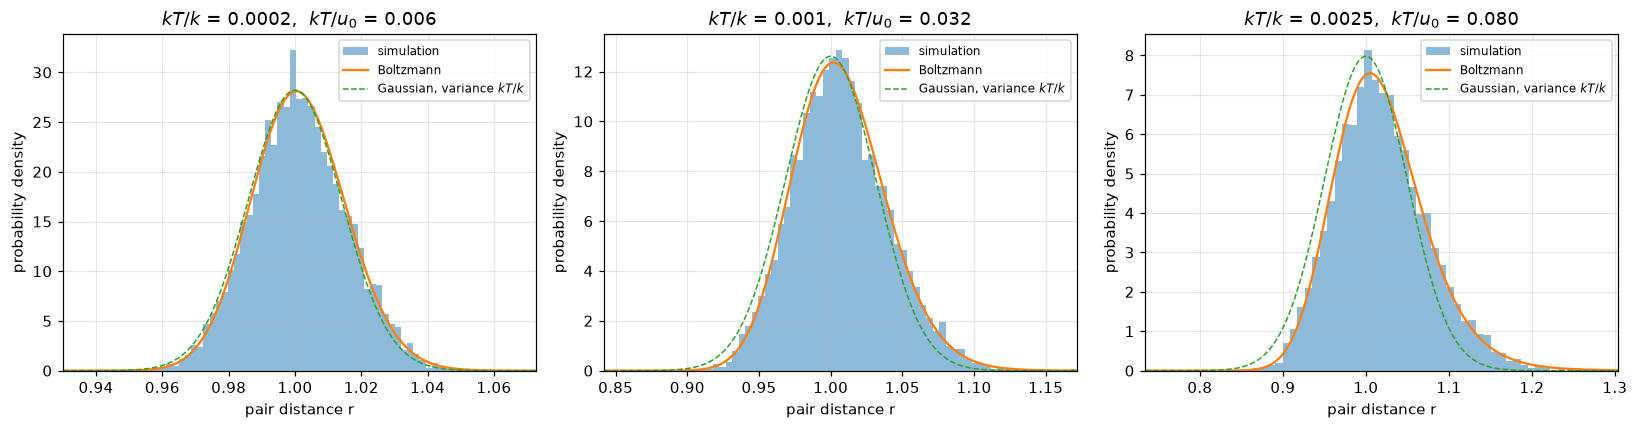

In [3]:
def potential(r, well_depth, equilibrium_distance, steepness):
    t = np.exp(steepness * (1.0 - (r / equilibrium_distance) ** 2))
    return well_depth * t * (t - 2.0)


def boltzmann(r, thermal_energy, **shape):
    # restricted to the bound region: beyond the cutoff a pair would be free and never return
    weight = r**2 * np.exp(-(potential(r, **shape) - potential(shape["equilibrium_distance"], **shape)) / thermal_energy)
    return weight / np.trapezoid(weight, r)


ratios = ["0.0002", "0.001", "0.0025"]
fig, axes = plt.subplots(1, len(ratios), figsize=(15, 4))

print(f"{'kT/k':>8}{'kT/u0':>9}{'variance':>12}{'kT/k':>11}{'Boltzmann':>12}{'sim vs kT/k':>14}{'sim vs Boltzmann':>19}")
for ax, ratio in zip(axes, ratios):
    params, table = load(f"noise_pair_{ratio}.csv")
    distances = table["distance"]
    shape = dict(well_depth=params["well_depth"], equilibrium_distance=params["equilibrium_distance"], steepness=params["steepness"])
    thermal_energy = params["thermal_energy"]

    r = np.linspace(0.7, 1.6, 4000) * params["equilibrium_distance"]
    density = boltzmann(r, thermal_energy, **shape)
    mean = np.trapezoid(r * density, r)
    boltzmann_variance = np.trapezoid((r - mean) ** 2 * density, r)
    harmonic_variance = thermal_energy / params["stiffness"]

    ax.hist(distances, bins=60, density=True, alpha=0.5, label="simulation")
    ax.plot(r, density, label="Boltzmann")
    ax.plot(r, np.exp(-(r - params["equilibrium_distance"]) ** 2 / (2 * harmonic_variance)) / np.sqrt(2 * np.pi * harmonic_variance),
            linestyle="--", linewidth=1, label="Gaussian, variance $kT/k$")
    spread = 5 * np.sqrt(boltzmann_variance)
    ax.set(xlim=(mean - spread, mean + spread), xlabel="pair distance r", ylabel="probability density",
           title=f"$kT/k$ = {ratio},  $kT/u_0$ = {thermal_energy / params['well_depth']:.3f}")
    ax.legend(fontsize=8)

    variance = distances.var()
    print(f"{ratio:>8}{thermal_energy / params['well_depth']:>9.3f}{variance:>12.3e}{harmonic_variance:>11.3e}{boltzmann_variance:>12.3e}"
          f"{100 * (variance / harmonic_variance - 1):>+13.1f}%{100 * (variance / boltzmann_variance - 1):>+18.1f}%")

    # 8000 samples, roughly independent; the finite timestep widens the distribution by about 2%
    assert abs(variance / boltzmann_variance - 1) < 0.08, f"kT/k = {ratio}: the pair is not in thermal equilibrium"

fig.tight_layout()

## When the noise is too strong: bonds break

The comparison above needs an equilibrium to exist. The well is only $u_0$ deep, and beyond the cutoff a pair
feels no force at all, so a pair that gets far enough never comes back. At $kT/k = 0.005$, which is
$kT = 0.16\,u_0$, this starts to happen within the run: the histogram grows a tail of pairs on their way out,
and the spread of the Boltzmann distribution depends on where one stops integrating: its variance is
0.011, 0.019 or 0.052 for an upper limit of 1.6, 2.0 or the cutoff. The simulated pairs have not had time to
fill the outer region, so no single curve describes them.

0.8% of the sampled pairs are stretched beyond 1.5 equilibrium distances; the largest distance is 2.32 (cutoff 2.5).


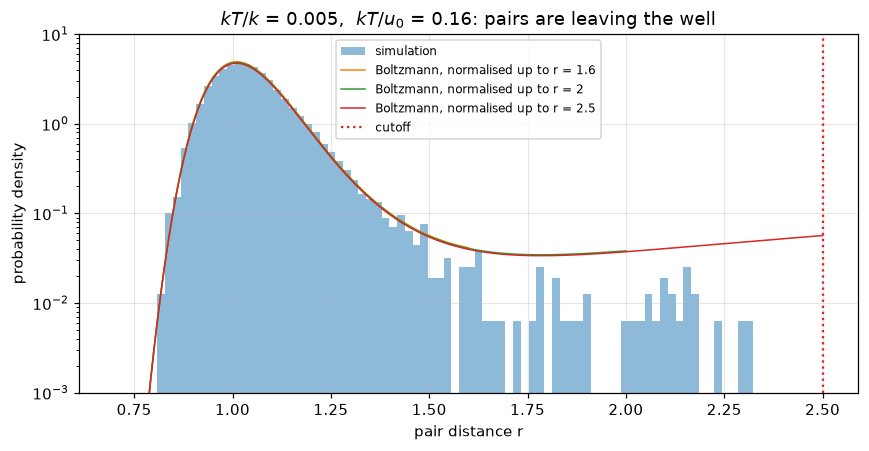

In [4]:
params, table = load("noise_pair_0.005.csv")
distances = table["distance"]
shape = dict(well_depth=params["well_depth"], equilibrium_distance=params["equilibrium_distance"], steepness=params["steepness"])
cutoff = params["cutoff_factor"] * params["equilibrium_distance"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(distances, bins=np.linspace(0.75, cutoff, 90), density=True, alpha=0.5, label="simulation")
for upper in (1.6, 2.0, cutoff):
    r = np.linspace(0.7, upper, 6000)
    ax.plot(r, boltzmann(r, params["thermal_energy"], **shape), linewidth=1, label=f"Boltzmann, normalised up to r = {upper:g}")
ax.axvline(cutoff, color="tab:red", linestyle=":", label="cutoff")
ax.set(yscale="log", ylim=(1e-3, 10), xlabel="pair distance r", ylabel="probability density",
       title=f"$kT/k$ = 0.005,  $kT/u_0$ = {params['thermal_energy'] / params['well_depth']:.2f}: pairs are leaving the well")
ax.legend(fontsize=8)
fig.tight_layout()

stretched = (distances > 1.5 * params["equilibrium_distance"]).mean()
print(f"{100 * stretched:.1f}% of the sampled pairs are stretched beyond 1.5 equilibrium distances; "
      f"the largest distance is {distances.max():.2f} (cutoff {cutoff:g}).")
assert stretched > 0.002, "this run is meant to show bonds starting to break"

## Reading the result

- **Where an equilibrium exists, the simulated distances follow the Boltzmann distribution**, including the
  skew towards larger distances as the temperature rises. The remaining excess of 2–3% in the variance is
  mostly the forward-Euler timestep, which widens an equilibrium distribution by the factor
  $1/(1 - k\,\Delta t/\eta)$, here 2%.
- **$kT/k$ is only the low-temperature limit** of the variance. The well is softer on its outer side, so the
  true spread is larger, by 9% already at $kT/k = 0.001$.
- **Choosing $D$:** what matters is $kT = D\eta$ against the well depths. With $kT$ below about a tenth of
  $u_0$ bonds hold over the times simulated here and the noise only makes elements jiggle and rearrange.
  At $kT = 0.16\,u_0$ single bonds already break. Inter-cellular wells are shallower than intra-cellular ones,
  so contacts between cells break first.

### Caveats

- **A single pair is the weakest case.** An element inside a cell is held by many neighbours at once, so a
  cell survives temperatures at which an isolated pair separates. That has not been quantified here.
- **Escape is permanent.** The potential is cut off, so nothing brings a separated pair back together.
- **The noise is the same for every element** and does not depend on the cell or on the local environment.
- **`velocity` excludes the noise.** The stored velocity of an element is the deterministic part $F/\eta$ only.